# Heal the Bay Plastics collected in July of the 2026 Water Year 

What amount and types of plastic debris were logged by the Heal the Bay Organization during the month of July?

# Other possiblilies and follow ups that I can do after I understand the database
What does the monthly pattern look like?
Are more plastics collected during the rainy season months (October - March) than the dry months?
Do I need to normalize for number of events?
Do the items of plastics differ in summer and winter?

# Database source and intro notes
I used the Marina Debris Tracker app from NOAA. https://debristracker.org/data.

For my csv export, I filtered the database on 'Heal the Bay' as the organization and the time period Oct 1, 2025 - October 1, 2026 (the rainy season officially starts an Oct 1 each year. This period is defined as the 2026 Water Year). This will give me all the data collected in the name of Heal the Bay for the time period listed. There may be more Los Angels data, but I chose this source for sorting this monstrous database for my export.

In [1]:
#Import the csv as a database.
import pandas as pd
df = pd.read_csv('Noaa_HTB_2025.csv')

In [2]:
df.shape

(7883, 18)

In [3]:
df.head()

,list_name,itemname,material,quantity,description,latitude,longitude,altitude,radius,location,timestamp,dt,project_name,username,manual_upload,event_name,id,log_index
0,Heal the Bay,Plastic Beverage Bottles,PLASTIC ITEMS,1,NaN,33.998101,-118.486507,1.016494,5.662080,"Santa Monica, California, United States of Ame...",20251004195250,2025-10-04 19:52:50,Adopt-A-Beach,Rockstarla,0,NaN,3242157,85481
1,Heal the Bay,Plastic Beverage Bottles,PLASTIC ITEMS,1,NaN,33.999765,-118.486336,4.871593,6.323596,"Santa Monica, California, United States of Ame...",20251011183335,2025-10-11 18:33:35,Adopt-A-Beach,Rockstarla,0,NaN,3246573,85655
2,Heal the Bay,Plastic Beverage Bottles,PLASTIC ITEMS,1,NaN,33.998099,-118.484937,7.688945,7.291821,"Santa Monica, California, United States of Ame...",20251011195920,2025-10-11 19:59:20,Adopt-A-Beach,Rockstarla,0,NaN,3246797,85655
3,Heal the Bay,Plastic Beverage Bottles,PLASTIC ITEMS,1,NaN,33.981287,-118.458813,5.108501,11.750344,"Marina del Rey, California, United States of A...",20251012164520,2025-10-12 16:45:20,Default,eadams,0,NaN,3246920,85664
4,Heal the Bay,Plastic Beverage Bottles,PLASTIC ITEMS,15,NaN,33.981304,-118.458825,4.076367,5.991241,"Marina del Rey, California, United States of A...",20251012165511,2025-10-12 16:55:11,NaN,ljdayi,0,NaN,3246950,85665


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7883 entries, 0 to 7882
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   list_name      7883 non-null   str    
 1   itemname       7883 non-null   str    
 2   material       7883 non-null   str    
 3   quantity       7883 non-null   int64  
 4   description    5 non-null      str    
 5   latitude       7883 non-null   float64
 6   longitude      7883 non-null   float64
 7   altitude       7883 non-null   float64
 8   radius         7883 non-null   float64
 9   location       7883 non-null   str    
 10  timestamp      7883 non-null   int64  
 11  dt             7883 non-null   str    
 12  project_name   7311 non-null   str    
 13  username       7883 non-null   str    
 14  manual_upload  7883 non-null   int64  
 15  event_name     0 non-null      float64
 16  id             7883 non-null   int64  
 17  log_index      7883 non-null   int64  
dtypes: float64(5), int6

In [5]:
# Check out types of materials in the 'material' column
unique_materials = df['material'].unique()

print(unique_materials)

<ArrowStringArray>
[             'PLASTIC ITEMS',                'GLASS ITEMS',
                'METAL ITEMS',                 'FOAM ITEMS',
            'SMOKING RELATED',          'PAPER/FIBER ITEMS',
 'MEDICAL & PERSONAL HYGIENE']
Length: 7, dtype: str


In [6]:
# Check out types of items in the 'plastic items' itemnames
plastic_items = df[df['material'] == 'PLASTIC ITEMS']['itemname'].unique()

In [7]:
print(plastic_items)

<ArrowStringArray>
[              'Plastic Beverage Bottles',
                           'Plastic Bags',
            'Plastic Snack Bags/Wrappers',
              'Plastic Bottle Caps/Rings',
                           '6-Pack Rings',
        'Newspaper Ties/ Strapping Bands',
               'Plastic Straws/ Stirrers',
     'Fishing Line/ Nets/  Lures/ Floats',
 'Cleaning Liquid Bottle/Large Container',
                       'Balloons/Ribbons',
                         'Plastic Pieces',
                              'Cups/Lids',
                               'Utensils',
                                 'Plates']
Length: 14, dtype: str


# Initial data base cleaning steps and extracting a smaller dataset
1. I will reduce my working database to fewer columns and save one identifying column in case I need to join the databases later. [itemname], [material], [quantity], [location], [dt], [id]
2. The date is dtype string so needs to be changed to datetime
3. There are numerous materials with numerous subclasses (or items). Three ways to go here:
   a. only look at plastic
   b. look at plastic and foam
   c. summarize the quanitities in all catogories and then zoom in on plastics.
   I said I would only be loking at plastic so I will pull only the plastic material into my database.

# AI Prompt for initial cleaning and shrinking of my working database
Tool: Gemini
Prompt: You are helping to create a smaller database and clean some data: (1)My CSV has 18 columns. I want to create a new df, named plastic_df, that includes only 6 of the 18 columns, they are: [itemname], [material], [quantity], [location], [dt], [id]. (2) The date in the dt column is a string, change dtype to datetime. (3) There are numerous "materials' values. Only pull 'plastic' material into this database. I should end up with a smaller database that has only 6 columns and only plastic materials. Explain each step in comments.

# Verify data before implementing AI Code


# AI Code inserted here

In [8]:
# 1. Create a new DataFrame (plastic_df) keeping only the 6 required columns
columns_to_keep = ['itemname', 'material', 'quantity', 'location', 'dt', 'id']
plastic_df = df[columns_to_keep].copy()

# 2. Convert the 'dt' column from a string to datetime format
plastic_df['dt'] = pd.to_datetime(plastic_df['dt'])

# 3. Filter the DataFrame to only include rows where the material is plastic 
# (using .str.lower() to catch variations like 'PLASTIC ITEMS' or 'plastic')
plastic_df = plastic_df[plastic_df['material'].str.lower().str.contains('plastic')]

# Display the first few rows of your new filtered and cleaned database
plastic_df.head()

,itemname,material,quantity,location,dt,id
0,Plastic Beverage Bottles,PLASTIC ITEMS,1,"Santa Monica, California, United States of Ame...",2025-10-04 19:52:50,3242157
1,Plastic Beverage Bottles,PLASTIC ITEMS,1,"Santa Monica, California, United States of Ame...",2025-10-11 18:33:35,3246573
2,Plastic Beverage Bottles,PLASTIC ITEMS,1,"Santa Monica, California, United States of Ame...",2025-10-11 19:59:20,3246797
3,Plastic Beverage Bottles,PLASTIC ITEMS,1,"Marina del Rey, California, United States of A...",2025-10-12 16:45:20,3246920
4,Plastic Beverage Bottles,PLASTIC ITEMS,15,"Marina del Rey, California, United States of A...",2025-10-12 16:55:11,3246950


In [10]:
#Verify shape
plastic_df.shape

(5038, 6)

In [13]:
#Verify material type
unique_materials = plastic_df['material'].unique()

print(unique_materials)

<ArrowStringArray>
['PLASTIC ITEMS']
Length: 1, dtype: str


In [15]:
#Verify dt set as dtyoe datetime
plastic_df.info()

<class 'pandas.DataFrame'>
Index: 5038 entries, 0 to 7731
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   itemname  5038 non-null   str           
 1   material  5038 non-null   str           
 2   quantity  5038 non-null   int64         
 3   location  5038 non-null   str           
 4   dt        5038 non-null   datetime64[us]
 5   id        5038 non-null   int64         
dtypes: datetime64[us](1), int64(2), str(3)
memory usage: 676.5 KB


# AI Prompt 2
You are helping me create plots using the plastic_df database I want to create (1) A plot to show total quantity of 
plastic each month. (2) Show a plot of the total quantity of each itemname in the month of July (3) plot of the quantity of each itemname in the month of July 
as a percent of the total items

Write Python using pandas and seaborn to: organize the data and produce the charts. Explain each step in comments.



# Expalantions:
Explanation of Each Step:
Monthly Aggregation (to_period('M')): Converts your dt datetime timestamps into monthly periods so you can aggregate and sum up all plastic quantities per month using Seaborn's bar plot.

July Filtering (.dt.month == 7): Filters out rows belonging to July across your dataset, grouping by itemname and sorting them to highlight which specific plastic items appear most frequently.

Percentage Normalization: Takes the summed July item quantities, divides them by the overall sum of July plastics, and multiplies by 100 to easily visualize each item's relative compositional footprint.

# AI code pasted here

/var/folders/2y/kr5wp1qj7jnb5crn5pzyncjh0000gn/T/ipykernel_97123/1330570592.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


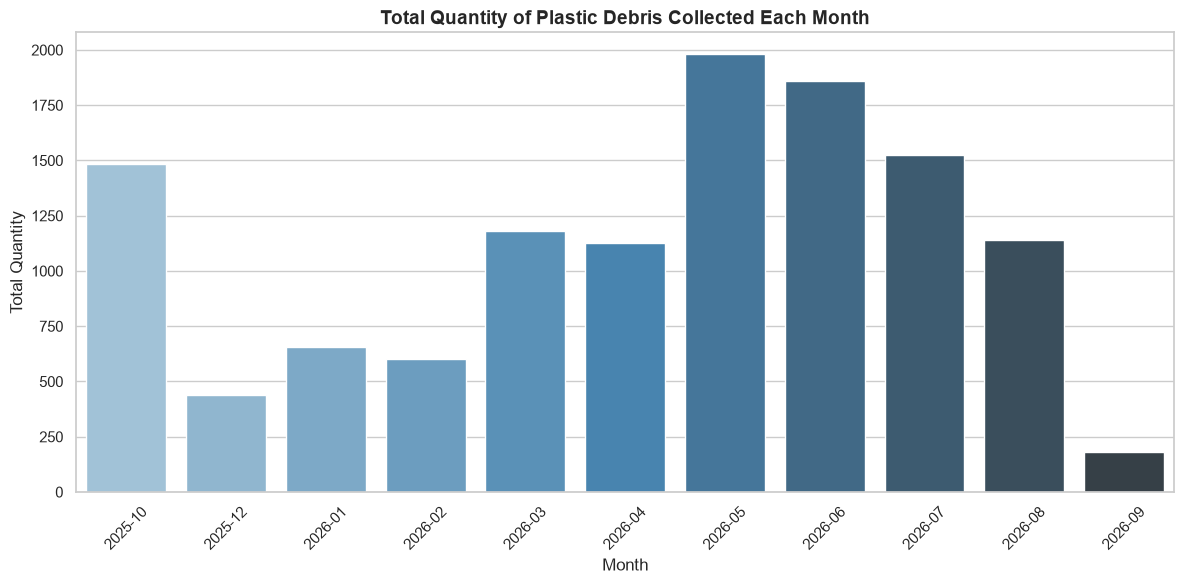

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set overall seaborn aesthetic style for clean visualizations
sns.set_theme(style="whitegrid")

# ==========================================
# 1. Total Quantity of Plastic Each Month
# ==========================================
# Create a temporary copy and extract the year-month period for grouping
monthly_df = plastic_df.copy()
monthly_df['year_month'] = monthly_df['dt'].dt.to_period('M')

# Group by the year-month and sum the quantities of plastic items
monthly_quantity = monthly_df.groupby('year_month')['quantity'].sum().reset_index()
monthly_quantity['year_month'] = monthly_quantity['year_month'].astype(str) # Convert period to string for plotting

# Plotting total quantity by month
plt.figure(figsize=(12, 6))
sns.barplot(
    data=monthly_quantity, 
    x='year_month', 
    y='quantity', 
    palette='Blues_d'
)
plt.title('Total Quantity of Plastic Debris Collected Each Month', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Total Quantity', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

/var/folders/2y/kr5wp1qj7jnb5crn5pzyncjh0000gn/T/ipykernel_97123/4043163721.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


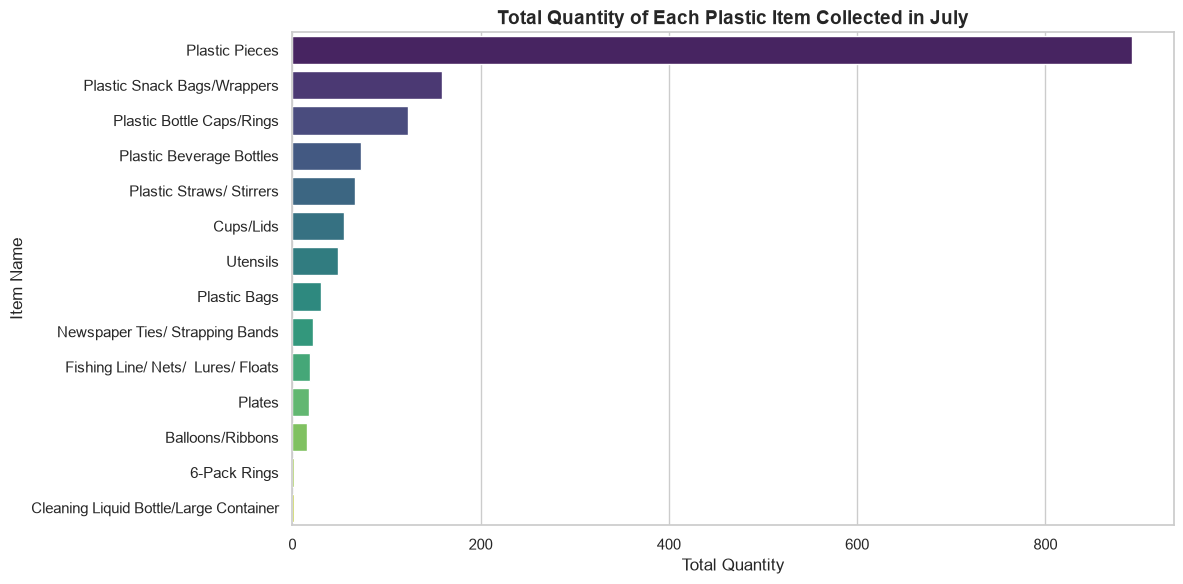

In [17]:
# ==========================================
# 2. Total Quantity of Each Itemname in July
# ==========================================
# Filter data specifically for the month of July (regardless of the year, or specify a year like 2026)
july_df = plastic_df[plastic_df['dt'].dt.month == 7].copy()

# Group by itemname and sum their quantities, then sort descending
july_items = july_df.groupby('itemname')['quantity'].sum().reset_index()
july_items = july_items.sort_values(by='quantity', ascending=False)

# Plotting total quantity of each item name in July
plt.figure(figsize=(12, 6))
sns.barplot(
    data=july_items, 
    x='quantity', 
    y='itemname', 
    palette='viridis'
)
plt.title('Total Quantity of Each Plastic Item Collected in July', fontsize=14, fontweight='bold')
plt.xlabel('Total Quantity', fontsize=12)
plt.ylabel('Item Name', fontsize=12)
plt.tight_layout()
plt.show()

/var/folders/2y/kr5wp1qj7jnb5crn5pzyncjh0000gn/T/ipykernel_97123/3273204807.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


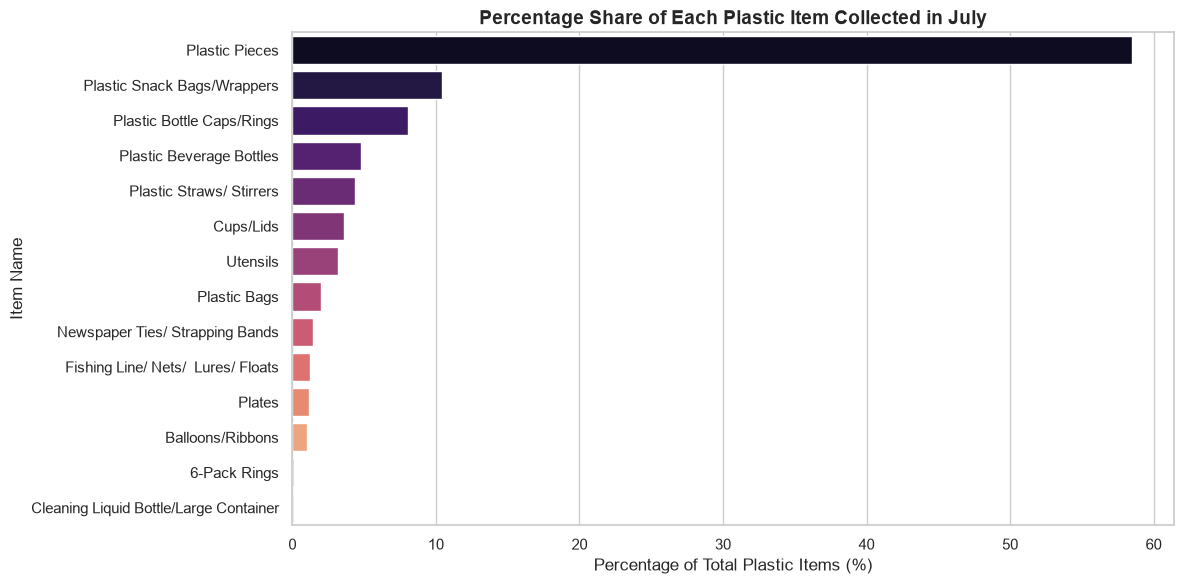

In [18]:
# ==========================================
# 3. Quantity of Each Itemname in July as a % of Total July Items
# ==========================================
# Calculate percentage share relative to the total quantity collected in July
july_items['percentage'] = (july_items['quantity'] / july_items['quantity'].sum()) * 100

# Plotting percentage breakdown of items in July
plt.figure(figsize=(12, 6))
sns.barplot(
    data=july_items, 
    x='percentage', 
    y='itemname', 
    palette='magma'
)
plt.title('Percentage Share of Each Plastic Item Collected in July', fontsize=14, fontweight='bold')
plt.xlabel('Percentage of Total Plastic Items (%)', fontsize=12)
plt.ylabel('Item Name', fontsize=12)
plt.tight_layout()
plt.show()

I asked Gemini to provide the coding for step #3 to be a pie chart instead of bar chart. Code is below, explanations are here: 

Explanations:
plt.pie(...): Replaces the bar plot function with matplotlib's pie chart builder.

autopct='%1.1f%%': Automatically calculates and labels each slice with its percentage value formatted to one decimal place.

startangle=140: Rotates the starting angle of the chart so the labels and slices are easier to read and less clustered.

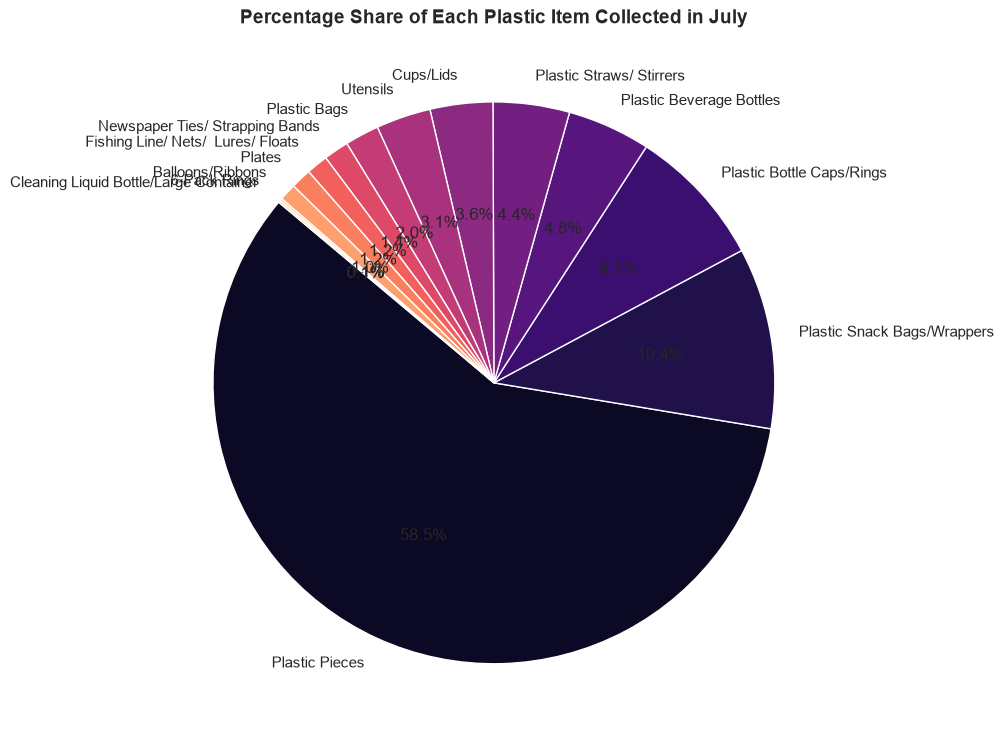

In [19]:
# ==========================================
# 3. Quantity of Each Itemname in July as a % of Total July Items (Pie Chart)
# ==========================================
# Calculate percentage share relative to the total quantity collected in July
july_items['percentage'] = (july_items['quantity'] / july_items['quantity'].sum()) * 100

# Plotting percentage breakdown of items in July as a pie chart
plt.figure(figsize=(10, 10))
plt.pie(
    july_items['quantity'], 
    labels=july_items['itemname'], 
    autopct='%1.1f%%', 
    startangle=140,
    colors=sns.color_palette('magma', len(july_items))
)

plt.title('Percentage Share of Each Plastic Item Collected in July', fontsize=14, fontweight='bold')
plt.ylabel('') # Hides the default y-label for a cleaner look
plt.tight_layout()
plt.show()

#Verification steps using original df and plastic_df created by AI

In [8]:
#Verify the july plastic items in initial database with code.
jul_df = df[
    (df['material'].str.lower() == 'plastic items') & 
    (df['dt'] >= '2026-07-01') & 
    (df['dt'] <= '2026-07-31')
]

# Display the filtered DataFrame
jul_df

,list_name,itemname,material,quantity,description,latitude,longitude,altitude,radius,location,timestamp,dt,project_name,username,manual_upload,event_name,id,log_index
109,Heal the Bay,Plastic Beverage Bottles,PLASTIC ITEMS,9,NaN,33.764729,-118.182716,4.600000,5.000000,"Long Beach, California, United States of America",20260708190558,2026-07-08 19:05:58,Default,Rjuricich,0,NaN,3395798,90719
110,Heal the Bay,Plastic Beverage Bottles,PLASTIC ITEMS,1,NaN,33.856082,-118.399561,6.029503,4.964093,"Redondo Beach, California, United States of Am...",20260709182712,2026-07-09 18:27:12,Default,Catguzman,0,NaN,3396902,90732
111,Heal the Bay,Plastic Beverage Bottles,PLASTIC ITEMS,1,NaN,33.856097,-118.399593,5.783989,2.946711,"Redondo Beach, California, United States of Am...",20260709182716,2026-07-09 18:27:16,Default,Catguzman,0,NaN,3396903,90732
112,Heal the Bay,Plastic Beverage Bottles,PLASTIC ITEMS,1,NaN,33.856097,-118.399593,5.657829,2.610155,"Redondo Beach, California, United States of Am...",20260709182717,2026-07-09 18:27:17,Default,Catguzman,0,NaN,3396904,90732
113,Heal the Bay,Plastic Beverage Bottles,PLASTIC ITEMS,3,NaN,33.856096,-118.399595,5.510887,2.575186,"Redondo Beach, California, United States of Am...",20260709182719,2026-07-09 18:27:19,Default,Catguzman,0,NaN,3396905,90732
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7719,Heal the Bay,Plates,PLASTIC ITEMS,4,NaN,33.860509,-118.396047,17.868664,5.297858,"Hermosa Beach, California, United States of Am...",20260711214051,2026-07-11 21:40:51,Default,MollyD,0,NaN,3399197,90783
7720,Heal the Bay,Plates,PLASTIC ITEMS,1,NaN,34.055413,-118.242884,100.300003,14.158000,"Los Angeles, California, United States of America",20260713211042,2026-07-13 21:10:42,Default,Rebrahim94,0,NaN,3400742,90818
7721,Heal the Bay,Plates,PLASTIC ITEMS,2,NaN,33.762739,-118.181054,1.848815,4.730187,"Long Beach, California, United States of America",20260722172237,2026-07-22 17:22:37,Default,Rjuricich,0,NaN,3408463,91073
7722,Heal the Bay,Plates,PLASTIC ITEMS,2,NaN,33.762753,-118.181049,1.374607,4.733775,"Long Beach, California, United States of America",20260722180623,2026-07-22 18:06:23,Default,Rjuricich,0,NaN,3408481,91073


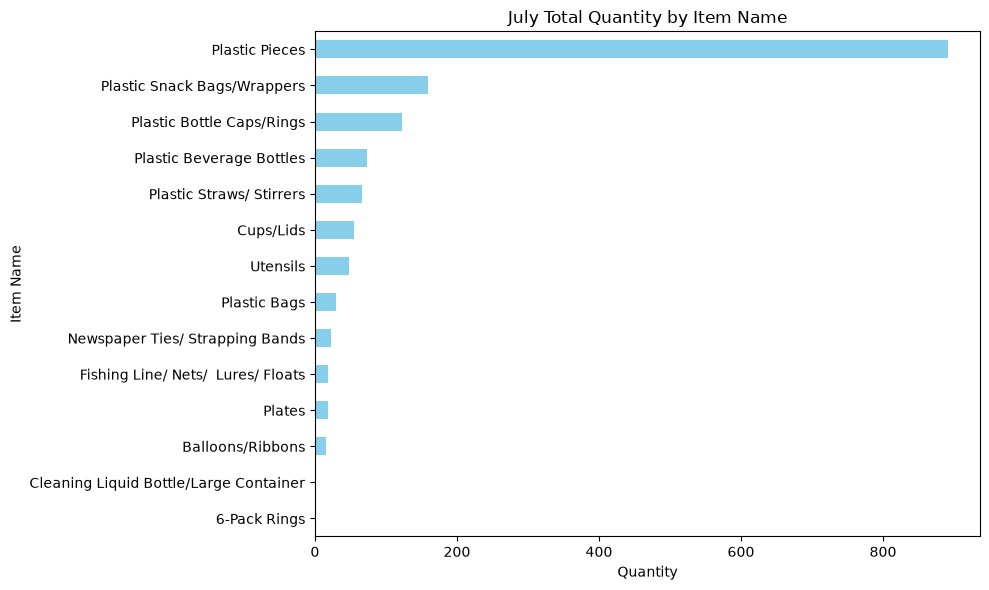

In [9]:
import matplotlib.pyplot as plt

# Group by itemname and sum the quantities, then sort them for a cleaner chart
item_quantities = jul_df.groupby('itemname')['quantity'].sum().sort_values(ascending=True)

# Create the bar plot
plt.figure(figsize=(10, 6))
item_quantities.plot(kind='barh', color='skyblue')

# Add titles and labels
plt.title('July Total Quantity by Item Name')
plt.xlabel('Quantity')
plt.ylabel('Item Name')

# Show the plot
plt.tight_layout()
plt.show()

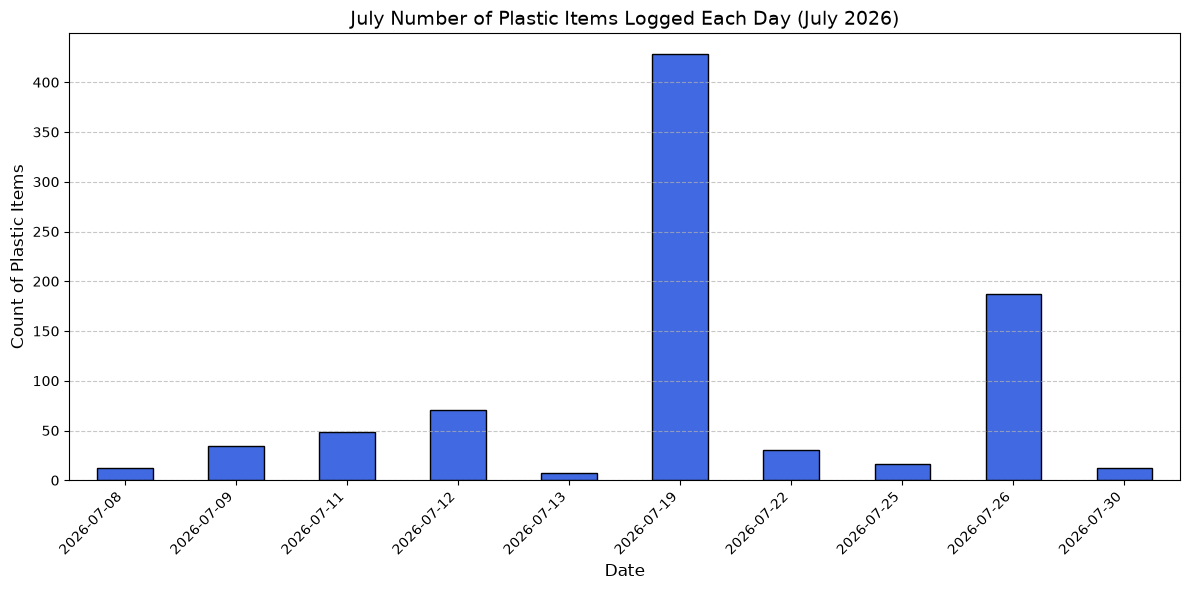

In [11]:
import matplotlib.pyplot as plt


mask = (
    (df['material'].str.lower() == 'plastic items') & 
    (df['dt'] >= '2026-07-01') & 
    (df['dt'] <= '2026-07-31')
)
filtered_df = df[mask].copy()

# 2. Extract just the date part (ignoring the timestamp) and count occurrences per day
# If you want to count total quantities instead of row entries, replace .size() with .sum() on 'quantity'
daily_counts = filtered_df.groupby(filtered_df['dt'].dt.date).size()

# 3. Create the time-series line/bar plot
plt.figure(figsize=(12, 6))
daily_counts.plot(kind='bar', color='royalblue', edgecolor='black')

# Add titles and labels
plt.title('July Number of Plastic Items Logged Each Day (July 2026)', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Count of Plastic Items', fontsize=12)

# Format the x-axis ticks for readability
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [12]:
# Dec data

dec_df = df[
    (df['material'].str.lower() == 'plastic items') & 
    (df['dt'] >= '2025-12-01') & 
    (df['dt'] <= '2025-12-31')
]

# Display the filtered DataFrame
dec_df

,list_name,itemname,material,quantity,description,latitude,longitude,altitude,radius,location,timestamp,dt,project_name,username,manual_upload,event_name,id,log_index
31,Heal the Bay,Plastic Beverage Bottles,PLASTIC ITEMS,3,NaN,33.762673,-118.181156,2.318428,3.041544,"Long Beach, California, United States of America",20251201190345,2025-12-01 19:03:45,Default,Rjuricich,0,NaN,3288308,86833
32,Heal the Bay,Plastic Beverage Bottles,PLASTIC ITEMS,3,NaN,33.763731,-118.181439,6.334333,125.426017,"Long Beach, California, United States of America",20251201193654,2025-12-01 19:36:54,Default,Rjuricich,0,NaN,3288324,86833
33,Heal the Bay,Plastic Beverage Bottles,PLASTIC ITEMS,1,NaN,33.865030,-118.402803,4.342696,2.250800,"Hermosa Beach, California, United States of Am...",20251206183755,2025-12-06 18:37:55,Default,cshultz@gmail.com,0,NaN,3292249,86893
34,Heal the Bay,Plastic Beverage Bottles,PLASTIC ITEMS,5,NaN,33.882321,-118.397826,56.247434,4.723623,"Manhattan Beach, California, United States of ...",20251208202204,2025-12-08 20:22:04,Default,Marieavila,0,NaN,3293821,86911
35,Heal the Bay,Plastic Beverage Bottles,PLASTIC ITEMS,3,NaN,33.763568,-118.179258,2.466648,3.218060,"Long Beach, California, United States of America",20251222220132,2025-12-22 22:01:32,Default,Rjuricich,0,NaN,3299914,87075
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7548,Heal the Bay,Utensils,PLASTIC ITEMS,4,NaN,33.882321,-118.397827,56.134302,4.748323,"Manhattan Beach, California, United States of ...",20251208202207,2025-12-08 20:22:07,Default,Marieavila,0,NaN,3293824,86911
7549,Heal the Bay,Utensils,PLASTIC ITEMS,3,NaN,33.763567,-118.179264,2.350141,4.748652,"Long Beach, California, United States of America",20251222220148,2025-12-22 22:01:48,Default,Rjuricich,0,NaN,3299918,87075
7550,Heal the Bay,Utensils,PLASTIC ITEMS,3,NaN,33.763798,-118.177941,2.859694,4.692961,"Long Beach, California, United States of America",20251222223106,2025-12-22 22:31:06,Default,Rjuricich,0,NaN,3299931,87075
7551,Heal the Bay,Utensils,PLASTIC ITEMS,2,NaN,33.763805,-118.177929,1.632685,4.621479,"Long Beach, California, United States of America",20251222224956,2025-12-22 22:49:56,Default,Rjuricich,0,NaN,3299943,87075


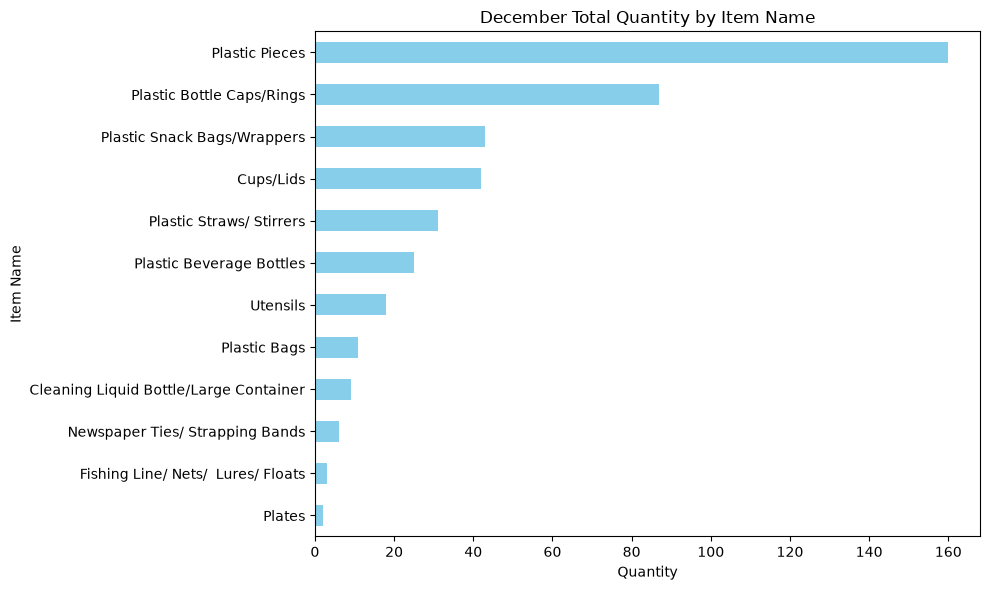

In [13]:
import matplotlib.pyplot as plt

# Group by itemname and sum the quantities, then sort them for a cleaner chart
item_quantities = dec_df.groupby('itemname')['quantity'].sum().sort_values(ascending=True)

# Create the bar plot
plt.figure(figsize=(10, 6))
item_quantities.plot(kind='barh', color='skyblue')

# Add titles and labels
plt.title('December Total Quantity by Item Name')
plt.xlabel('Quantity')
plt.ylabel('Item Name')

# Show the plot
plt.tight_layout()
plt.show()

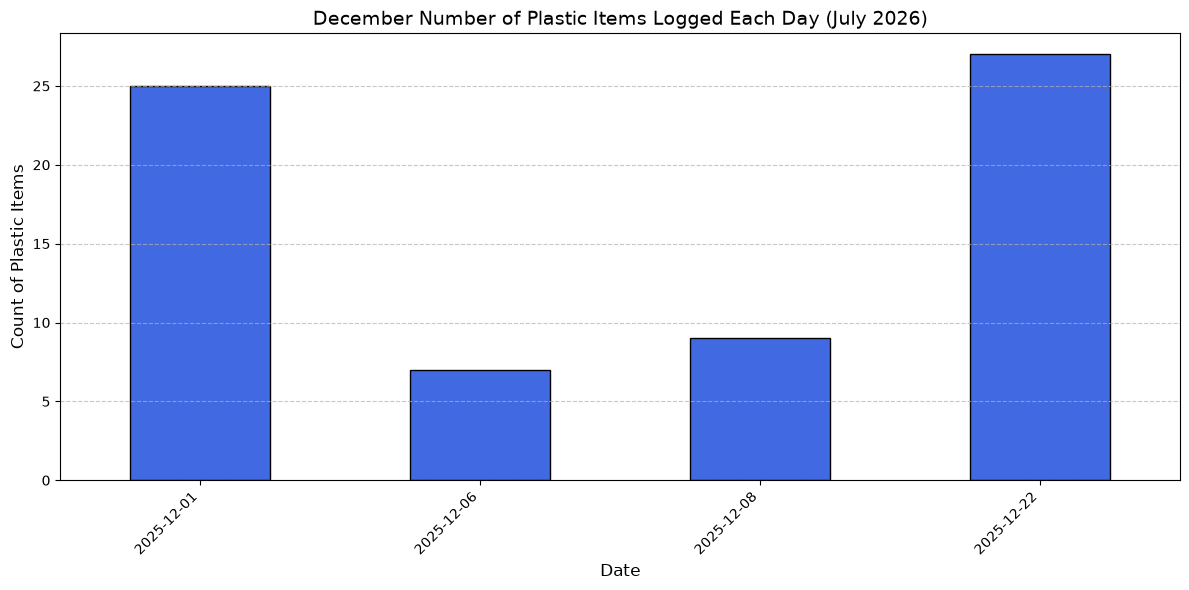

In [14]:
import matplotlib.pyplot as plt


mask = (
    (df['material'].str.lower() == 'plastic items') & 
    (df['dt'] >= '2025-12-01') & 
    (df['dt'] <= '2025-12-31')
)
filtered_df = df[mask].copy()

# 2. Extract just the date part (ignoring the timestamp) and count occurrences per day
# If you want to count total quantities instead of row entries, replace .size() with .sum() on 'quantity'
daily_counts = filtered_df.groupby(filtered_df['dt'].dt.date).size()

# 3. Create the time-series line/bar plot
plt.figure(figsize=(12, 6))
daily_counts.plot(kind='bar', color='royalblue', edgecolor='black')

# Add titles and labels
plt.title('December Number of Plastic Items Logged Each Day (July 2026)', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Count of Plastic Items', fontsize=12)

# Format the x-axis ticks for readability
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()